In [1]:
%cd ..
%reset -f

/home/remi/jul26_bds_blood_cells


In [ ]:
# from src.features.blood_cell_metadata import BloodCellMetadata
# from src.cfg import MUNICH_DIR, MUNICH_METADATA_PATH

# df_munich = BloodCellMetadata(root_dir=MUNICH_DIR, source="Munich", read_image=True).get_df()
# df_munich.to_csv(MUNICH_METADATA_PATH, index=False)


In [ ]:
# from src.features.blood_cell_metadata import BloodCellMetadata
# from src.cfg import BARCELONA_DIR, BARCELONA_METADATA_PATH

# df_barcelona = BloodCellMetadata(root_dir=BARCELONA_DIR, source="Barcelona", read_image=True).get_df()
# df_barcelona.to_csv(BARCELONA_METADATA_PATH, index=False)

In [ ]:
import pandas as pd
from src.cfg import MUNICH_METADATA_PATH, BARCELONA_METADATA_PATH

df_munich = pd.read_csv(MUNICH_METADATA_PATH)
df_barcelona = pd.read_csv(BARCELONA_METADATA_PATH)

In [20]:
df_all = pd.concat([df_munich, df_barcelona], ignore_index=True)
df_all.head(10)

,source,relative_path,class_folder,class_code,file_type,file_size,height,width,channels,brightness,...,hue_mean,saturation_mean,value_mean,sharpness,r_mean,g_mean,b_mean,r_std,g_std,b_std
0,Munich,data/PKG-AML-Cytomorphology_LMU/BAS/BAS_0001.tiff,Basophil,BAS,.tiff,640154,400.0,"(400,)",3.0,186.536219,...,133.641531,49.909206,211.009750,14.844416,201.968513,174.517663,207.835688,41.358678,61.312453,23.727950
1,Munich,data/PKG-AML-Cytomorphology_LMU/BAS/BAS_0002.tiff,Basophil,BAS,.tiff,640154,400.0,"(400,)",3.0,159.338831,...,115.424612,45.197131,182.840519,222.473679,174.189200,148.426038,176.558337,86.067659,88.369451,79.621849
2,Munich,data/PKG-AML-Cytomorphology_LMU/BAS/BAS_0003.tiff,Basophil,BAS,.tiff,640154,400.0,"(400,)",3.0,211.228138,...,83.956719,30.367019,225.728694,19.861072,221.114937,204.425138,220.211725,30.296722,55.451898,22.145198
3,Munich,data/PKG-AML-Cytomorphology_LMU/BAS/BAS_0004.tiff,Basophil,BAS,.tiff,640154,400.0,"(400,)",3.0,189.074675,...,128.538331,55.839981,217.314087,14.773192,208.230281,175.504075,208.610944,43.633724,68.798305,25.698862
4,Munich,data/PKG-AML-Cytomorphology_LMU/BAS/BAS_0005.tiff,Basophil,BAS,.tiff,640154,400.0,"(400,)",3.0,183.197369,...,123.430731,48.770894,206.965706,13.795417,193.949400,173.551994,204.626637,49.375719,69.004647,28.938153
5,Munich,data/PKG-AML-Cytomorphology_LMU/BAS/BAS_0006.tiff,Basophil,BAS,.tiff,640154,400.0,"(400,)",3.0,141.979187,...,105.882487,45.721981,165.865475,290.487991,156.671781,130.850531,160.764344,95.445220,93.883104,91.034574
6,Munich,data/PKG-AML-Cytomorphology_LMU/BAS/BAS_0007.tiff,Basophil,BAS,.tiff,640154,400.0,"(400,)",3.0,187.374313,...,109.538406,54.638481,214.404525,31.509495,201.276356,176.139938,208.702206,52.676258,75.734923,27.173988
7,Munich,data/PKG-AML-Cytomorphology_LMU/BAS/BAS_0008.tiff,Basophil,BAS,.tiff,640154,400.0,"(400,)",3.0,176.612269,...,131.877588,55.451037,203.424825,23.402642,194.773687,163.401381,197.026869,38.814920,61.120340,22.943523
8,Munich,data/PKG-AML-Cytomorphology_LMU/BAS/BAS_0009.tiff,Basophil,BAS,.tiff,640154,400.0,"(400,)",3.0,165.757650,...,129.403550,64.024012,194.394013,24.155036,177.934294,154.557694,191.566612,62.388376,69.570202,32.745119
9,Munich,data/PKG-AML-Cytomorphology_LMU/BAS/BAS_0010.tiff,Basophil,BAS,.tiff,640154,400.0,"(400,)",3.0,199.360938,...,99.847794,46.256756,223.339188,13.742857,215.482738,188.203988,214.604681,37.772207,65.353418,20.832997


Displaying image for source: Barcelona, class_code: BAS, image_path: data/PBC_dataset_normal_DIB/basophil/BA_100102.jpg
Displaying image for source: Barcelona, class_code: EBO, image_path: data/PBC_dataset_normal_DIB/erythroblast/ERB_101031.jpg
Displaying image for source: Barcelona, class_code: EOS, image_path: data/PBC_dataset_normal_DIB/eosinophil/EO_100213.jpg
Displaying image for source: Barcelona, class_code: IG, image_path: data/PBC_dataset_normal_DIB/ig/IG_101958.jpg
Displaying image for source: Barcelona, class_code: LYT, image_path: data/PBC_dataset_normal_DIB/lymphocyte/LY_100275.jpg
Displaying image for source: Barcelona, class_code: MMZ, image_path: data/PBC_dataset_normal_DIB/ig/MMY_100949.jpg
Displaying image for source: Barcelona, class_code: MON, image_path: data/PBC_dataset_normal_DIB/monocyte/MO_100695.jpg
Displaying image for source: Barcelona, class_code: MYB, image_path: data/PBC_dataset_normal_DIB/ig/MY_100038.jpg
Displaying image for source: Barcelona, class_cod

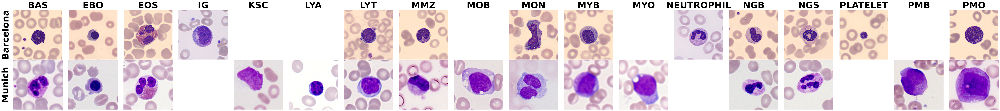

In [67]:
from pathlib import Path
import matplotlib.pyplot as plt
from src.features.common import load_image

classes = sorted(df_all["class_code"].dropna().unique())
sources = ["Barcelona", "Munich"]

fig, axes = plt.subplots(len(sources), len(classes), figsize=(len(classes) * 4, len(sources) * 4))

for row, source in enumerate(sources):
    for col, class_code in enumerate(classes):
        ax = axes[row, col]
        ax.axis("off")

        data = df_all[(df_all["source"] == source) & (df_all["class_code"] == class_code)]

        if not data.empty:
            image_path = Path(data.iloc[0]["relative_path"])
            print(f"Displaying image for source: {source}, class_code: {class_code}, image_path: {image_path}")
            ax.imshow(load_image(image_path))

        if row == 0:
            ax.set_title(class_code, fontsize=11*4, fontweight="bold", pad=5)
    axes[row, 0].text(-0.15, 0.5, source, transform=axes[row, 0].transAxes, rotation=90, va="center", ha="center", fontsize=11*4, fontweight="bold")

plt.subplots_adjust(
    left=0.05,
    right=0.99,
    top=0.88,
    bottom=0.03,
    wspace=0.02,
    hspace=0.02
)

plt.show()


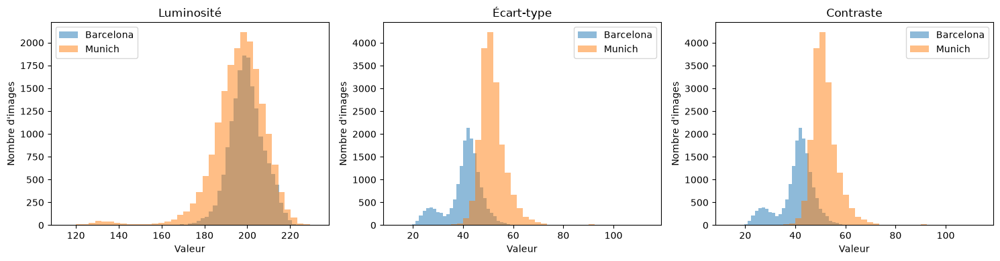

In [21]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for source, group in df_all.groupby("source"):
    axes[0].hist(group["brightness"], bins=40, alpha=0.5, label=source)
    axes[1].hist(group["std"], bins=40, alpha=0.5, label=source)
    axes[2].hist(group["contrast"], bins=40, alpha=0.5, label=source)

axes[0].set_title("Luminosité")
axes[1].set_title("Écart-type")
axes[2].set_title("Contraste")

for ax in axes:
    ax.legend()
    ax.set_xlabel("Valeur")
    ax.set_ylabel("Nombre d'images")

plt.tight_layout()
plt.show()

In [22]:
import plotly.express as px
df = df_all.copy()
fig = px.box(
    df,
    x="class_code",
    y="brightness",
    color="source",
    category_orders={"class_code": df["class_code"].unique()},
    points=False,
    title="Luminosité des images par classe et par source",
    labels={"class_code": "Classe", "brightness": "Luminosité", "source": "Source"}
)

fig.update_layout(
    xaxis_title="Classe cellulaire",
    yaxis_title="Luminosité moyenne",
    boxmode="group"
)

fig.show()

In [23]:
fig = px.box(
    df,
    x="class_code",
    y="contrast",
    color="source",
    category_orders={"class_code": df["class_code"].unique()},
    points=False,
    title="Contraste des images par classe et par source",
    labels={"class_code": "Classe", "contrast": "Contraste", "source": "Source"}
)

fig.update_layout(
    xaxis_title="Classe cellulaire",
    yaxis_title="Contraste",
    boxmode="group"
)

fig.show()

In [24]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go

fig = make_subplots(
    rows=1,
    cols=3,
    subplot_titles=("Hauteur", "Largeur", "Ratio d'aspect")
)

for source in df["source"].unique():
    data = df[df["source"] == source]

    fig.add_trace(
        go.Box(y=data["height"], name=source, boxpoints=False),
        row=1, col=1
    )

    fig.add_trace(
        go.Box(y=data["width"], name=source, boxpoints=False, showlegend=False),
        row=1, col=2
    )

    fig.add_trace(
        go.Box(y=data["aspect_ratio"], name=source, boxpoints=False, showlegend=False),
        row=1, col=3
    )

fig.update_yaxes(title_text="Pixels", row=1, col=1)
fig.update_yaxes(title_text="Pixels", row=1, col=2)
fig.update_yaxes(title_text="Ratio", row=1, col=3)

fig.update_layout(
    title="Comparaison des dimensions et du ratio d'aspect des images",
    boxmode="group"
)

fig.show()

In [10]:
df_plot = df.copy()
df_plot["file_size_kb"] = df_plot["file_size"] / 1024

fig = px.box(
    df_plot,
    x="source",
    y="file_size_kb",
    points=False,
    log_y=True,
    title="Poids des fichiers par source",
    labels={
        "source": "Source",
        "file_size_kb": "Taille du fichier (Ko)"
    }
)

fig.show()

In [25]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import numpy as np

metric = "std"

fig = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=("PBC / Barcelone", "LMU / Munich")
)

for col, source in enumerate(["Barcelona", "Munich"], start=1):
    data = df[df["source"] == source]["std"]

    threshold = np.percentile(data, 2)
    n_low = (data < threshold).sum()
    n_total = len(data)
    pct_low = 100 * n_low / n_total

    fig.add_trace(
        go.Histogram(
            x=data,
            nbinsx=50,
            name=source,
            showlegend=False
        ),
        row=1,
        col=col
    )

    fig.add_vline(
        x=threshold,
        line_dash="dash",
        row=1,
        col=col
    )

    fig.add_annotation(
        x=threshold,
        y=1,
        yref="paper",
        text=f"Seuil 2e percentile : {threshold:.2f}<br>{n_low} images ({pct_low:.2f} %)",
        showarrow=True,
        arrowhead=2,
        row=1,
        col=col
    )

fig.update_xaxes(title_text="Écart-type des pixels (std)", row=1, col=1)
fig.update_xaxes(title_text="Écart-type des pixels (std)", row=1, col=2)
fig.update_yaxes(title_text="Nombre d'images", row=1, col=1)

fig.update_layout(
    title="Distribution de la netteté et identification des images potentiellement floues",
    bargap=0.05
)

fig.show()


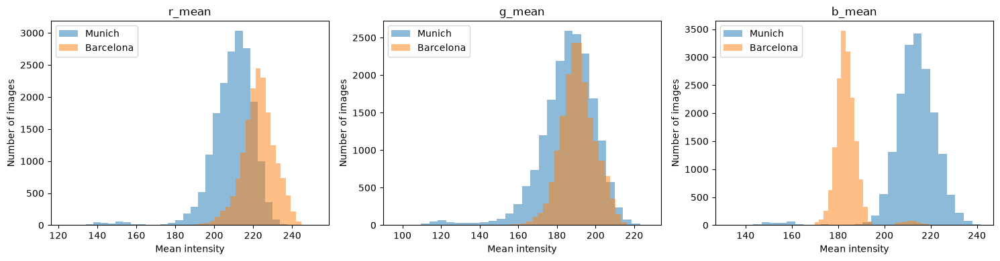

In [28]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, channel in zip(axes, ["r_mean", "g_mean", "b_mean"]):
    for source in df_all["source"].unique():
        data = df_all[df_all["source"] == source][channel].dropna()
        ax.hist(data, bins=30, alpha=0.5, label=source)

    ax.set_title(channel)
    ax.set_xlabel("Mean intensity")
    ax.set_ylabel("Number of images")
    ax.legend()

plt.tight_layout()
plt.show()

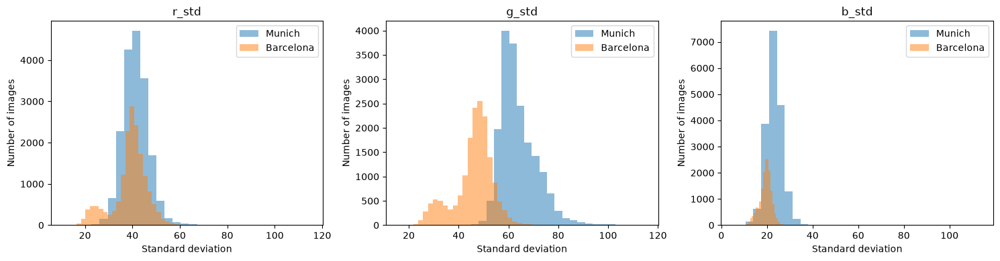

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, channel in zip(axes, ["r_std", "g_std", "b_std"]):
    for source in df_all["source"].unique():
        data = df_all[df_all["source"] == source][channel].dropna()
        ax.hist(data, bins=30, alpha=0.5, label=source)

    ax.set_title(channel)
    ax.set_xlabel("Standard deviation")
    ax.set_ylabel("Number of images")
    ax.legend()

plt.tight_layout()
plt.show()